<a href="https://colab.research.google.com/github/Shravani408/Netflix-Data-Cleaning-Using-Python-Description-/blob/Shravani408-patch-1/Country_Wise_Netflix_Content_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles.csv


In [4]:
df = pd.read_csv('netflix_titles.csv', encoding='latin1')

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [5]:
df.shape

(8790, 10)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [7]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


In [8]:
df = df.drop_duplicates(subset='show_id')

In [9]:
df['country'] = df['country'].fillna('')

In [10]:
df[['title', 'country']].head(10)

,title,country
0,Dick Johnson Is Dead,United States
1,Ganglands,France
2,Midnight Mass,United States
3,Confessions of an Invisible Girl,Brazil
4,Sankofa,United States
5,The Great British Baking Show,United Kingdom
6,The Starling,United States
7,Motu Patlu in the Game of Zones,India
8,Je Suis Karl,Germany
9,Motu Patlu in Wonderland,India


In [11]:
country_df = df[df['country'] != ''].copy()

country_df['country'] = country_df['country'].str.split(',')

country_df = country_df.explode('country')

country_df['country'] = country_df['country'].str.strip()

country_df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [12]:
country_counts = country_df.groupby('country')['title'].nunique()

country_counts = country_counts.sort_values(ascending=False)

print(country_counts)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Not Given          287
                  ... 
Slovenia             1
Puerto Rico          1
Somalia              1
West Germany         1
Zimbabwe             1
Name: title, Length: 86, dtype: int64


In [13]:
top_10 = country_counts.head(10)

print(top_10)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: title, dtype: int64


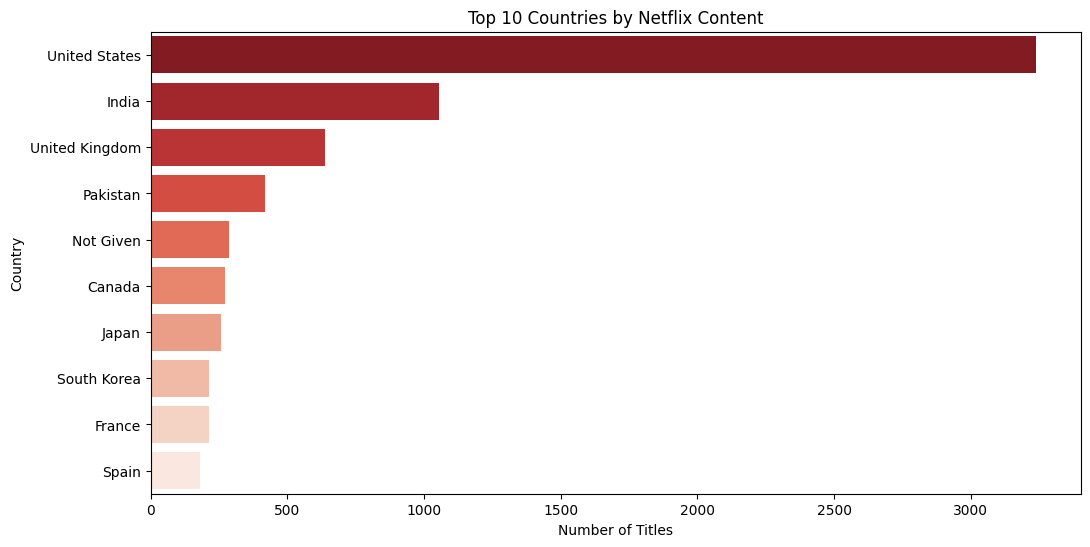

In [14]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=top_10.values,
    y=top_10.index,
    hue=top_10.index,
    palette='Reds_r',
    legend=False
)

plt.title('Top 10 Countries by Netflix Content')

plt.xlabel('Number of Titles')

plt.ylabel('Country')

plt.show()

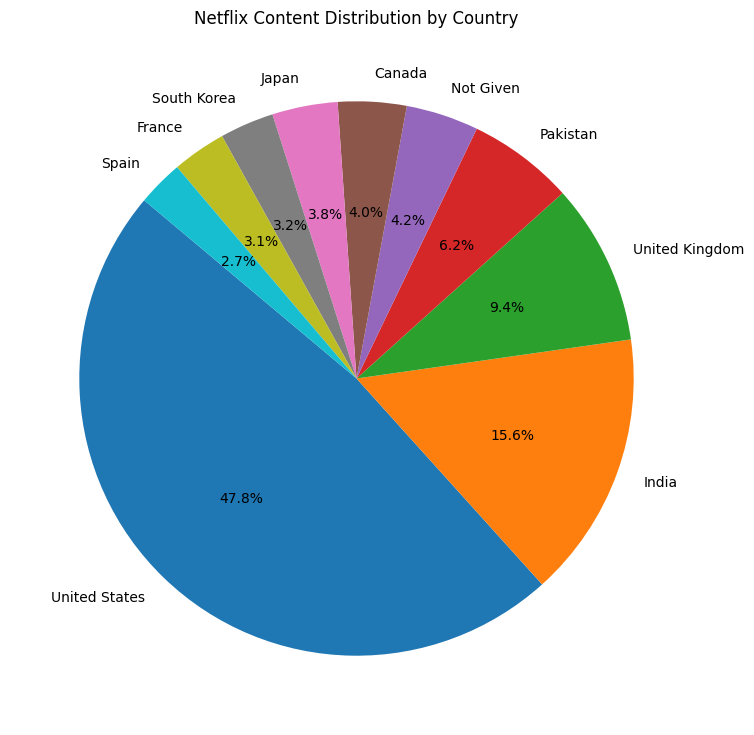

In [15]:
plt.figure(figsize=(9,9))

plt.pie(
    top_10.values,
    labels=top_10.index,
    autopct='%1.1f%%',
    startangle=140
)

plt.title('Netflix Content Distribution by Country')

plt.show()

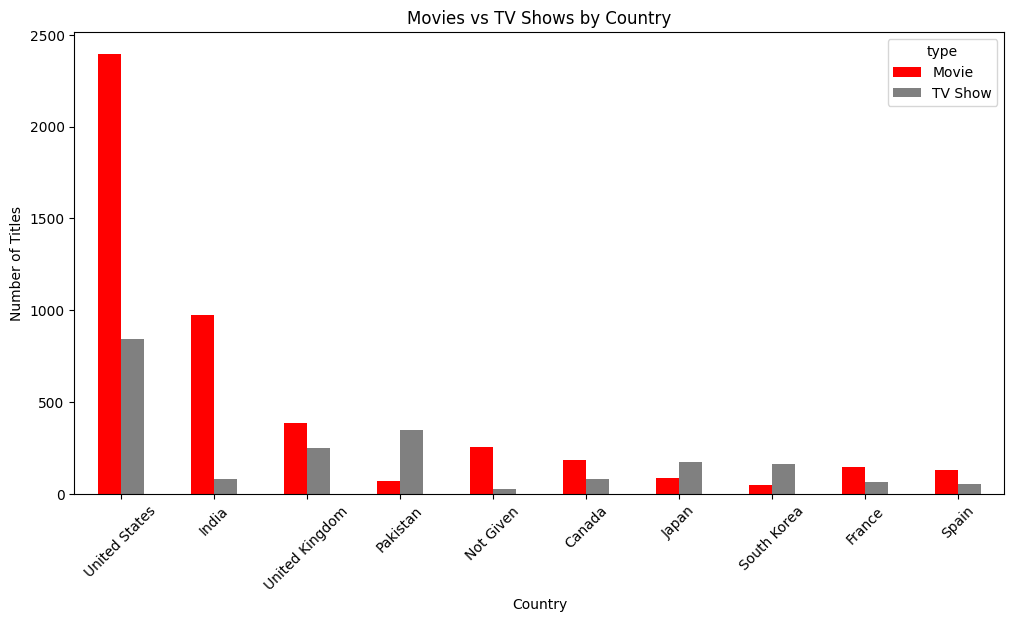

In [16]:
content_type = country_df.pivot_table(
    index='country',
    columns='type',
    values='title',
    aggfunc='nunique',
    fill_value=0
)

top_countries = country_counts.head(10).index

content_type_top = content_type.loc[top_countries]

content_type_top.plot(
    kind='bar',
    figsize=(12,6),
    color=['red', 'grey']
)

plt.title('Movies vs TV Shows by Country')

plt.xlabel('Country')

plt.ylabel('Number of Titles')

plt.xticks(rotation=45)

plt.show()